# Runtime curve walkthrough: hail × real estate

Reads the proposed artifact and calls the curves through the cell's reference evaluator, the way a Hazard M3
consumer would. Damage only: no frequency, no yearly loss. See
[`00_curve_curation_walkthrough.ipynb`](00_curve_curation_walkthrough.ipynb) for how the curves are built.

In [1]:
from pathlib import Path
import json
import re
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display


def find_repo_root() -> Path:
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        if (p / "docs/cells").is_dir() and (p / "scripts/reference_helpers").is_dir():
            return p
    raise RuntimeError("Run this notebook from inside the Damage_Modeling repository.")


ROOT = find_repo_root()
CELL_ID = "hail_real_estate"
PROP = ROOT / "docs/cells" / CELL_ID / "proposed"
ARTIFACT_PATH = PROP / "hail_real_estate__model_v0_1__docs_r1__curve_artifact.json"
REG = "hail_real_estate__model_v0_1__docs_r1"  # tag of the cell registers (source, claims, tiers, decisions)
OUT = ROOT / "notebooks/hail/real_estate/outputs"
OUT.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT / "scripts/reference_helpers"))
import hail_real_estate_curve_eval as ev  # the cell's reference evaluator

pd.set_option("display.max_colwidth", 160)
pd.set_option("display.width", 220)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

ART = json.loads(ARTIFACT_PATH.read_text())
# Replacement cost new from the Hazard reference profiles r1 (Q3 2025 Dallas prices). Illustration only:
# the artifacts withhold scenario dollars until the consumer qualifies each building value.
BUDGETS_USD = {"RE_RES_SFD_1S_SLAB": 405_000, "RE_IND_WAREHOUSE": 11_000_000, "RE_COM_OFFICE_3S_SLAB": 10_800_000}
NAMES = {"RE_RES_SFD_1S_SLAB": "House", "RE_IND_WAREHOUSE": "Warehouse", "RE_COM_OFFICE_3S_SLAB": "Office",
         "RE_COM_LOWRISE": "Retail (unbound)"}


def table(name: str) -> pd.DataFrame:
    return pd.read_csv(PROP / name)


def save(fig, name: str) -> None:
    fig.savefig(OUT / name, dpi=110, bbox_inches="tight", metadata={"Software": None})


def decision_log(path: Path) -> pd.DataFrame:
    """Decision-log rows: ID, whether JL decided it, and the decision text (shortened)."""
    rows = []
    for line in path.read_text().splitlines():
        if not line.startswith("| D-"):
            continue
        cells = [c.strip() for c in line.strip().strip("|").split(" | ")]
        text = re.sub(r"\*\*", "", cells[1])
        rows.append({"id": cells[0], "status": "JL decided" if "JL decided" in cells[1] else "proposed",
                      "decision": text if len(text) <= 240 else text[:240] + " …"})
    return pd.DataFrame(rows)


print("artifact:", ARTIFACT_PATH.relative_to(ROOT))
print(ART["cell_id"], "|", ART["semantic_damage_model_version"], "|", ART["damage_code_id"],
      "| promotion:", ART["promotion_status"], "| canonical:", ART["canonical_runtime_artifact"])


def call(request: dict) -> dict:
    """Send one request through the cell's reference evaluator; return a flat row."""
    try:
        out = ev.evaluate_damage_call(ART, request)
    except ev.DamageCallError as err:
        return {"status": "error", "curve_id": None, "damage_ratio": None, "reason": err.code}
    r = out["failure_unit_results"][0]
    return {"status": r["status"], "curve_id": r["curve_id"], "damage_ratio": r["scalar_central_dr"],
            "reason": "; ".join(r["withheld_reason_codes"]) or None}

ACK = "HRE_T4_WALLS_WINDOWS_SCREENING_2026_10_18"  # Tier-4 acknowledgement for the walls-and-windows unit
MM = 25.4

artifact: docs/cells/hail_real_estate/proposed/hail_real_estate__model_v0_1__docs_r1__curve_artifact.json
hail_real_estate | model v0.1 | HAIL_REAL_ESTATE_ROOF_THRESHOLD_SCREENING_V0_1 | promotion: proposed | canonical: False


## 1. What the artifact contains

In [2]:
identity = pd.DataFrame([
    {"field": "cell", "value": ART["cell_id"]},
    {"field": "damage code", "value": ART["damage_code_id"]},
    {"field": "model / docs", "value": f'{ART["semantic_damage_model_version"]} / {ART["documentation_revision"]}'},
    {"field": "lifecycle / promotion", "value": f'{ART["lifecycle_state"]} / {ART["promotion_status"]}'},
    {"field": "canonical runtime artifact", "value": ART["canonical_runtime_artifact"]},
    {"field": "model grade", "value": ART["model_grade"]},
])
display(identity)
units = pd.DataFrame([{k: u.get(k) for k in ("id", "treatment", "denominator")} for u in ART["failure_units"]])
display(units)
pathways = pd.DataFrame([{
    "pathway": p["pathway_id"],
    "axis field": p["hazard_axis"]["preferred_input_field"],
    "unit": p["hazard_axis"]["unit"],
    "valid range": p["hazard_axis"]["valid_range"],
    "selectors": ", ".join(s["field"] for s in p["selector_logic"] if s.get("required")),
    "conditioners": ", ".join(c["field"] for c in p["conditioner_logic"]) or "-",
    "records": len(p["curve_records"]),
} for p in ART["pathways"]])
display(pathways)

,field,value
0,cell,hail_real_estate
1,damage code,HAIL_REAL_ESTATE_ROOF_THRESHOLD_SCREENING_V0_1
2,model / docs,model v0.1 / docs r1
3,lifecycle / promotion,scaffold / proposed
4,canonical runtime artifact,False
5,model grade,screening_material_threshold_component_curves


,id,treatment,denominator
0,HRE_ROOF_COVER,primary_nonzero,replacement cost of the same building's roof cover (house shingles; warehouse steel panels; office TPO membrane and insulation)
1,HRE_WALLS_AND_WINDOWS,secondary_conditional,replacement cost of the same building's hail-vulnerable wall cladding and windows (house vinyl siding and windows; warehouse and office windows)
2,HRE_EXPOSED_EQUIPMENT,withheld,replacement cost of the outdoor AC condenser / rooftop units (not allocated)
3,HRE_BUILDING_CONTENTS,withheld,contents value (deferred)


,pathway,axis field,unit,valid range,selectors,conditioners,records
0,hail_impact,mesh_diameter_mm,mm,"[0.0, 203.2]",reference_building_id,-,6


## 2. Request contract

`failure_unit_id` is required. The walls-and-windows unit answers only when the request carries the Tier-4 acknowledgement `screening_assumption_set_id`.

In [3]:
display(pd.DataFrame(ART["evaluation_contract"]["accepted_axis_payloads"]))
display(pd.DataFrame(ART["pathways"][0]["selector_logic"])[["field", "required", "allowed", "effect"]])
display(pd.DataFrame(ART["pathways"][0]["failure_unit_coverage"]))

,pathway_id,mode,required_fields
0,hail_impact,hail_diameter_mm,[mesh_diameter_mm]


,field,required,allowed,effect
0,reference_building_id,True,"[RE_RES_SFD_1S_SLAB, RE_IND_WAREHOUSE, RE_COM_OFFICE_3S_SLAB]",Fixed identity of the reference building; picks its roof cover and wall/window parts.
1,screening_assumption_set_id,False,[HRE_T4_WALLS_WINDOWS_SCREENING_2026_10_18],Acknowledges the Tier-4 walls-and-windows screening assumptions; not needed for the roof cover.


,failure_unit_id,status,reason_codes
0,HRE_ROOF_COVER,conditional_numeric_screening_curve,[]
1,HRE_WALLS_AND_WINDOWS,conditional_synthetic_t4_curve,[]
2,HRE_EXPOSED_EQUIPMENT,withheld_not_zero,"[NO_RUNTIME_CURVE_FOR_PATHWAY_UNIT, FUNCTIONAL_EQUIPMENT_HAIL_EVIDENCE_NOT_FOUND]"
3,HRE_BUILDING_CONTENTS,withheld_not_zero,"[NO_RUNTIME_CURVE_FOR_PATHWAY_UNIT, CONTENTS_DEFERRED_SEPARATE_FAILURE_UNIT]"


## 3. All records, straight from the artifact

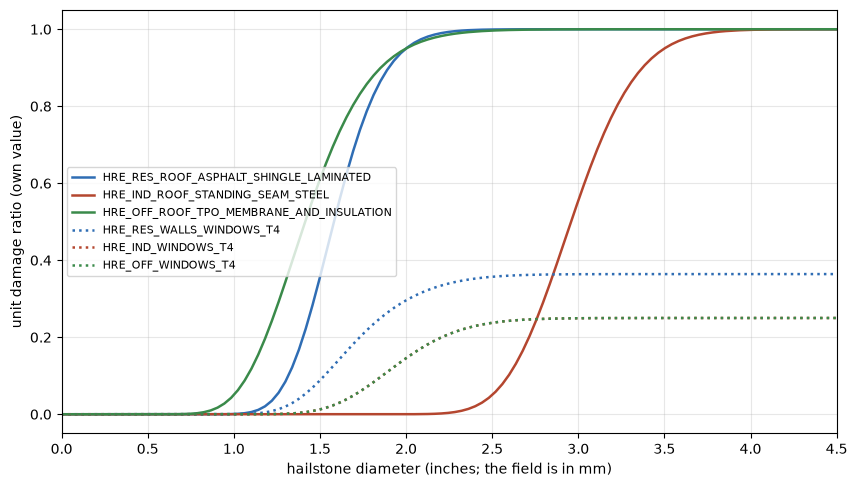

In [4]:
fig, ax = plt.subplots(figsize=(10, 5.5))
colors = {"RE_RES_SFD_1S_SLAB": "#2f6db4", "RE_IND_WAREHOUSE": "#b4462f", "RE_COM_OFFICE_3S_SLAB": "#3a8a4a"}
for r in ART["pathways"][0]["curve_records"]:
    b = r["selector_match"]["reference_building_id"]
    x, y = zip(*r["parameters"]["points"])
    ax.plot(np.array(x) / MM, y, "-" if r["failure_unit_id"] == "HRE_ROOF_COVER" else ":", color=colors[b], lw=1.8, label=r["curve_id"])
ax.set_xlim(0, 4.5)
ax.set_xlabel("hailstone diameter (inches; the field is in mm)")
ax.set_ylabel("unit damage ratio (own value)")
ax.legend(fontsize=8)
save(fig, "01_artifact_records.png")
plt.show()

## 4. Calling the curves

In [5]:
rows = []
for b in ("RE_RES_SFD_1S_SLAB", "RE_IND_WAREHOUSE", "RE_COM_OFFICE_3S_SLAB"):
    for unit in ("HRE_ROOF_COVER", "HRE_WALLS_AND_WINDOWS"):
        for size in (1.0, 1.25, 1.5, 2.0, 2.5, 3.0):
            req = {"pathway_id": "hail_impact", "failure_unit_id": unit, "reference_building_id": b, "mesh_diameter_mm": size * MM}
            if unit == "HRE_WALLS_AND_WINDOWS":
                req["screening_assumption_set_id"] = ACK
            rows.append({"building": NAMES[b], "unit": unit, "hail (in)": size, "unit DR": call(req)["damage_ratio"]})
grid = pd.DataFrame(rows).pivot_table(index=["unit", "building"], columns="hail (in)", values="unit DR").rename(columns=lambda c: f"{c:g} in")
display(grid.style.format("{:.1%}"))

## 5. Fail-closed behaviour

In [6]:
base = {"pathway_id": "hail_impact", "failure_unit_id": "HRE_ROOF_COVER", "reference_building_id": "RE_RES_SFD_1S_SLAB",
        "mesh_diameter_mm": 50.8}
cases = {
    "valid request (2 in, house roof)": base,
    "above 203.2 mm": {**base, "mesh_diameter_mm": 210.0},
    "negative size": {**base, "mesh_diameter_mm": -1.0},
    "walls and windows without the acknowledgement": {**base, "failure_unit_id": "HRE_WALLS_AND_WINDOWS"},
    "walls and windows with the acknowledgement": {**base, "failure_unit_id": "HRE_WALLS_AND_WINDOWS", "screening_assumption_set_id": ACK},
    "outdoor equipment": {**base, "failure_unit_id": "HRE_EXPOSED_EQUIPMENT"},
    "contents": {**base, "failure_unit_id": "HRE_BUILDING_CONTENTS"},
    "unknown building": {**base, "reference_building_id": "RE_COM_LOWRISE"},
}
display(pd.DataFrame([{"case": k, **call(v)} for k, v in cases.items()]))

,case,status,curve_id,damage_ratio,reason
0,"valid request (2 in, house roof)",conditional,HRE_RES_ROOF_ASPHALT_SHINGLE_LAMINATED,0.949725,NaN
1,above 203.2 mm,withheld,HRE_RES_ROOF_ASPHALT_SHINGLE_LAMINATED,NaN,ABOVE_SOURCE_VALID_RANGE
2,negative size,error,NaN,NaN,AXIS_OUTSIDE_VALID_RANGE
3,walls and windows without the acknowledgement,error,NaN,NaN,SCREENING_ASSUMPTION_SET_REQUIRED
4,walls and windows with the acknowledgement,conditional,HRE_RES_WALLS_WINDOWS_T4,0.295790,NaN
5,outdoor equipment,withheld,NaN,NaN,NO_RUNTIME_CURVE_FOR_PATHWAY_UNIT; FUNCTIONAL_EQUIPMENT_HAIL_EVIDENCE_NOT_FOUND
6,contents,withheld,NaN,NaN,NO_RUNTIME_CURVE_FOR_PATHWAY_UNIT; CONTENTS_DEFERRED_SEPARATE_FAILURE_UNIT
7,unknown building,error,NaN,NaN,REFERENCE_BUILDING_ID_UNKNOWN


## 6. From damage ratio to dollars (illustration)

Each unit's damage ratio is on that unit's own value, so dollars = unit DR × unit share × building value. The building values are the Hazard profile budgets, used only to show the arithmetic.

In [7]:
share = {u["id"]: u["share_of_structure_rcn"] for u in ART["failure_units"] if "share_of_structure_rcn" in u}
rows = []
for b, budget in BUDGETS_USD.items():
    roof = call({"pathway_id": "hail_impact", "failure_unit_id": "HRE_ROOF_COVER", "reference_building_id": b, "mesh_diameter_mm": 2 * MM})["damage_ratio"]
    rows.append({"building": NAMES[b], "building value": budget, "roof share": share["HRE_ROOF_COVER"][b],
                 "roof DR at 2 in": roof, "roof loss (illustration)": roof * share["HRE_ROOF_COVER"][b] * budget})
display(pd.DataFrame(rows).style.format({"building value": "${:,.0f}", "roof share": "{:.2%}", "roof DR at 2 in": "{:.1%}",
                                         "roof loss (illustration)": "${:,.0f}"}))

,building,building value,roof share,roof DR at 2 in,roof loss (illustration)
0,House,"$405,000",3.75%,95.0%,"$14,424"
1,Warehouse,"$11,000,000",12.00%,0.0%,$89
2,Office,"$10,800,000",2.70%,95.0%,"$276,984"


## 7. Capability

In [8]:
cap = ART["capability_declaration"]
rows = []
for pc in cap["pathway_capabilities"]:
    rows.append({"pathway": pc["pathway_id"], "failure-unit DR": pc["failure_unit_scalar_dr"],
                 "scenario loss": pc["scenario_loss_given_value_basis"], "spread": pc["curve_intrinsic_spread"],
                 "withheld units": ", ".join(w["failure_unit_id"] for w in pc.get("withheld_failure_units", []))})
display(pd.DataFrame(rows))
print("Annual and tail metrics:", cap["consumer_annual_metrics"]["status_before_promotion"],
      "(owner:", cap["consumer_annual_metrics"]["computation_owner"] + ")")
print("Promotion gate:", cap["promotion_gate"]["status"])
for item in cap["promotion_gate"]["required_before_canonical_use"]:
    print("  -", item)

,pathway,failure-unit DR,scenario loss,spread,withheld units
0,hail_impact,conditional,withheld,not_carried,"HRE_EXPOSED_EQUIPMENT, HRE_BUILDING_CONTENTS"


Annual and tail metrics: withheld_noncanonical_proposal (owner: downstream_consumer)
Promotion gate: blocked
  - owner accepts D-HRE-01 to D-HRE-16
  - consumer value qualification of each reference budget (shared with the other real-estate cells)
  - reviewer accepts the MESH75-as-hailstone axis reading and the Tier-4 walls-and-windows unit
  - independent review of the package


## 8. Not in this notebook

- Frequency and yearly loss belong to Hazard; the NRI comparison is `scripts/reference_helpers/hail_real_estate_nri_check.py`.
- The Hazard loader probe is `check_hail_real_estate_hazard_loader.py`.